<a href="https://colab.research.google.com/github/sejal-agarwal09/environmental-health-research/blob/main/environmental_health_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

print("Analysis environment ready.")

Analysis environment ready.


In [4]:
ces = pd.read_csv("calenviroscreen.csv")
places = pd.read_csv("places.csv")

income = pd.read_csv("acs_income.csv")
poverty = pd.read_csv("acs_poverty.csv")

print(ces.shape)
print(places.shape)

print(ces.columns.tolist())
print(places.columns.tolist())

(9106, 70)
(83522, 88)
['tract', 'zipcode', 'approx_loc', 'county', 'region', 'ACS2024Pop', 'CIscore', 'CIscoreP', 'ozone', 'ozoneP', 'pm', 'pmP', 'diesel', 'dieselP', 'pest', 'pestP', 'RSEIhaz', 'RSEIhazP', 'traffic', 'trafficP', 'drink', 'drinkP', 'lead', 'leadP', 'cleanups', 'cleanupsP', 'gwthreats', 'gwthreatsP', 'haz', 'hazP', 'iwb', 'iwbP', 'swis', 'swisP', 'SmATS', 'SmATSP', 'Pollution', 'PollutionS', 'PollutionP', 'asthma', 'asthmaP', 'lbw', 'lbwP', 'cvd', 'cvdP', 'diabetes', 'diabetesP', 'edu', 'eduP', 'ling', 'lingP', 'pov', 'povP', 'unemp', 'unempP', 'housingB', 'housingBP', 'PopChar', 'PopCharSco', 'PopCharP', 'pop_und10', 'pop_10_64', 'pop_ov64', 'hisp', 'white', 'black', 'amind', 'asian', 'pacisl', 'othmult']
['StateAbbr', 'StateDesc', 'CountyName', 'CountyFIPS', 'TractFIPS', 'TotalPopulation', 'TotalPop18plus', 'ACCESS2_CrudePrev', 'ACCESS2_Crude95CI', 'ARTHRITIS_CrudePrev', 'ARTHRITIS_Crude95CI', 'BINGE_CrudePrev', 'BINGE_Crude95CI', 'BPHIGH_CrudePrev', 'BPHIGH_Crude95C

In [5]:
print("CALENVIROSCREEN:")
display(ces[["tract", "county", "pm", "traffic"]].head(5))
print("Tract data type:", ces["tract"].dtype)

print("\nCDC PLACES:")
display(places[[
    "CountyName",
    "CountyFIPS",
    "TractFIPS",
    "CASTHMA_CrudePrev",
    "DIABETES_CrudePrev"
]].head(5))
print("Tract data type:", places["TractFIPS"].dtype)

print("\nACS INCOME:")
display(income[["GEO_ID", "NAME", "B19013_001E"]].head(5))

print("\nACS POVERTY:")
display(poverty[["GEO_ID", "NAME", "B17001_001E", "B17001_002E"]].head(5))

CALENVIROSCREEN:


,tract,county,pm,traffic
0,6001400100,Alameda,6.882156,539.417
1,6001400200,Alameda,6.950723,1229.853
2,6001400300,Alameda,7.120572,1244.499
3,6001400400,Alameda,6.916525,975.612
4,6001400500,Alameda,6.916525,321.162


Tract data type: int64

CDC PLACES:


,CountyName,CountyFIPS,TractFIPS,CASTHMA_CrudePrev,DIABETES_CrudePrev
0,Autauga,1001,1001020100,10.2,13.3
1,Autauga,1001,1001020200,10.8,15.8
2,Autauga,1001,1001020300,10.7,13.9
3,Autauga,1001,1001020400,9.6,12.8
4,Autauga,1001,1001020501,9.3,10.2


Tract data type: int64

ACS INCOME:


,GEO_ID,NAME,B19013_001E
0,Geography,Geographic Area Name,Estimate!!Median household income in the past ...
1,0100000US,United States,78538
2,0400000US06,California,96334
3,0500000US06085,"Santa Clara County, California",159674
4,1400000US06085500100,Census Tract 5001; Santa Clara County; California,152188



ACS POVERTY:


,GEO_ID,NAME,B17001_001E,B17001_002E
0,Geography,Geographic Area Name,Estimate!!Total:,Estimate!!Total:!!Income in the past 12 months...
1,1400000US06085500100,Census Tract 5001; Santa Clara County; California,7493,506
2,1400000US06085500200,Census Tract 5002; Santa Clara County; California,4351,607
3,1400000US06085500300,Census Tract 5003; Santa Clara County; California,4095,480
4,1400000US06085500400,Census Tract 5004; Santa Clara County; California,2649,111


In [6]:
print("CalEnviroScreen counties:")
print(ces["county"].unique())

print("\nCDC counties:")
print(places["CountyName"].unique()[:10])

CalEnviroScreen counties:
['Alameda' 'Alpine' 'Amador' 'Butte' 'Calaveras' 'Colusa' 'Contra Costa'
 'Del Norte' 'El Dorado' 'Fresno' 'Glenn' 'Humboldt' 'Imperial' 'Inyo'
 'Kern' 'Kings' 'Lake' 'Lassen' 'Los Angeles' 'Madera' 'Marin' 'Mariposa'
 'Mendocino' 'Merced' 'Modoc' 'Mono' 'Monterey' 'Napa' 'Nevada' 'Orange'
 'Placer' 'Plumas' 'Riverside' 'Sacramento' 'San Benito' 'San Bernardino'
 'San Diego' 'San Francisco' 'San Joaquin' 'San Luis Obispo' 'San Mateo'
 'Santa Barbara' 'Santa Clara' 'Santa Cruz' 'Shasta' 'Sierra' 'Siskiyou'
 'Solano' 'Sonoma' 'Stanislaus' 'Sutter' 'Tehama' 'Trinity' 'Tulare'
 'Tuolumne' 'Ventura' 'Yolo' 'Yuba']

CDC counties:
['Autauga' 'Baldwin' 'Barbour' 'Bibb' 'Blount' 'Bullock' 'Butler'
 'Calhoun' 'Chambers' 'Cherokee']


In [7]:

# ==========================================
# STEP 7: CLEAN AND COMBINE THE FOUR DATASETS
# Santa Clara County Environmental Health Project
# ==========================================

import pandas as pd
import numpy as np

# ------------------------------------------
# 1. CALENVIROSCREEN
# ------------------------------------------

ces_sc = ces[ces["county"] == "Santa Clara"].copy()

ces_sc["GEOID"] = (
    ces_sc["tract"].astype("int64").astype(str).str.zfill(11)
)

ces_clean = ces_sc[[
    "GEOID",
    "pm",
    "traffic"
]].copy()

ces_clean = ces_clean.rename(columns={
    "pm": "PM25",
    "traffic": "Traffic"
})

# Convert environmental variables to numeric
ces_clean["PM25"] = pd.to_numeric(
    ces_clean["PM25"], errors="coerce"
)

ces_clean["Traffic"] = pd.to_numeric(
    ces_clean["Traffic"], errors="coerce"
)


# ------------------------------------------
# 2. CDC PLACES
# ------------------------------------------

places_sc = places[
    (places["StateAbbr"] == "CA") &
    (places["CountyName"] == "Santa Clara")
].copy()

places_sc["GEOID"] = (
    places_sc["TractFIPS"].astype("int64").astype(str).str.zfill(11)
)

places_clean = places_sc[[
    "GEOID",
    "CASTHMA_CrudePrev",
    "DIABETES_CrudePrev"
]].copy()

places_clean = places_clean.rename(columns={
    "CASTHMA_CrudePrev": "Asthma",
    "DIABETES_CrudePrev": "Diabetes"
})

places_clean["Asthma"] = pd.to_numeric(
    places_clean["Asthma"], errors="coerce"
)

places_clean["Diabetes"] = pd.to_numeric(
    places_clean["Diabetes"], errors="coerce"
)


# ------------------------------------------
# 3. ACS MEDIAN HOUSEHOLD INCOME
# ------------------------------------------

income_sc = income.copy()

# Keep only census tract rows in Santa Clara County
income_sc["GEOID"] = (
    income_sc["GEO_ID"]
    .astype(str)
    .str.replace("1400000US", "", regex=False)
)

income_sc = income_sc[
    income_sc["GEOID"].str.startswith("06085")
].copy()

income_clean = income_sc[[
    "GEOID",
    "B19013_001E"
]].copy()

income_clean = income_clean.rename(columns={
    "B19013_001E": "Income"
})

income_clean["Income"] = pd.to_numeric(
    income_clean["Income"], errors="coerce"
)


# ------------------------------------------
# 4. ACS POVERTY
# ------------------------------------------

poverty_sc = poverty.copy()

poverty_sc["GEOID"] = (
    poverty_sc["GEO_ID"]
    .astype(str)
    .str.replace("1400000US", "", regex=False)
)

poverty_sc = poverty_sc[
    poverty_sc["GEOID"].str.startswith("06085")
].copy()

poverty_sc["TotalPopulation"] = pd.to_numeric(
    poverty_sc["B17001_001E"], errors="coerce"
)

poverty_sc["BelowPoverty"] = pd.to_numeric(
    poverty_sc["B17001_002E"], errors="coerce"
)

# Calculate poverty percentage
poverty_sc["Poverty"] = (
    poverty_sc["BelowPoverty"] /
    poverty_sc["TotalPopulation"]
) * 100

poverty_clean = poverty_sc[[
    "GEOID",
    "Poverty"
]].copy()


# ------------------------------------------
# 5. CHECK FOR DUPLICATE CENSUS TRACTS
# ------------------------------------------

datasets = {
    "CalEnviroScreen": ces_clean,
    "CDC PLACES": places_clean,
    "ACS Income": income_clean,
    "ACS Poverty": poverty_clean
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Number of tracts:", len(df))
    print("Duplicate GEOIDs:", df["GEOID"].duplicated().sum())


# ------------------------------------------
# 6. MERGE ALL FOUR DATASETS
# ------------------------------------------

combined = ces_clean.merge(
    places_clean,
    on="GEOID",
    how="inner",
    validate="one_to_one"
)

combined = combined.merge(
    income_clean,
    on="GEOID",
    how="inner",
    validate="one_to_one"
)

combined = combined.merge(
    poverty_clean,
    on="GEOID",
    how="inner",
    validate="one_to_one"
)


# ------------------------------------------
# 7. FINAL DATASET CHECK
# ------------------------------------------

print("\nFINAL DATASET")
print("Number of matched census tracts:", len(combined))

print("\nColumn names:")
print(combined.columns.tolist())

print("\nFirst five rows:")
display(combined.head())

print("\nMissing values:")
print(combined.isna().sum())

print("\nSummary statistics:")
display(combined.describe())

# Save the combined dataset
combined.to_csv(
    "santa_clara_environmental_health.csv",
    index=False
)

print("\nDataset saved successfully!")



CalEnviroScreen
Number of tracts: 408
Duplicate GEOIDs: 0

CDC PLACES
Number of tracts: 408
Duplicate GEOIDs: 0

ACS Income
Number of tracts: 408
Duplicate GEOIDs: 0

ACS Poverty
Number of tracts: 408
Duplicate GEOIDs: 0

FINAL DATASET
Number of matched census tracts: 408

Column names:
['GEOID', 'PM25', 'Traffic', 'Asthma', 'Diabetes', 'Income', 'Poverty']

First five rows:


,GEOID,PM25,Traffic,Asthma,Diabetes,Income,Poverty
0,06085500100,9.003107,1795.383,8.2,8.4,152188.0,6.752969
1,06085500200,9.023723,934.107,8.8,8.5,122238.0,13.950816
2,06085500300,8.873493,956.263,8.5,8.8,137917.0,11.721612
3,06085500400,8.718033,1288.229,8.7,8.8,151809.0,4.190260
4,06085500500,8.535666,1243.594,9.0,11.3,177625.0,4.609665



Missing values:
GEOID        0
PM25         0
Traffic      0
Asthma       0
Diabetes     0
Income      46
Poverty      0
dtype: int64

Summary statistics:


,PM25,Traffic,Asthma,Diabetes,Income,Poverty
count,408.000000,408.000000,408.000000,408.000000,362.000000,408.000000
mean,7.848914,922.760681,8.174020,10.335784,152614.270718,7.097297
std,0.511808,802.817514,0.830418,2.522370,47258.957066,5.591432
min,5.829805,86.362000,6.100000,2.700000,40167.000000,0.295082
25%,7.683203,352.373250,7.600000,9.000000,117350.500000,3.329567
50%,7.936032,609.004000,8.200000,10.050000,152514.500000,5.834437
75%,8.132558,1324.667000,8.800000,11.825000,186198.000000,8.974312
max,9.058060,5325.180000,11.500000,18.800000,249097.000000,47.139452



Dataset saved successfully!


In [8]:
# Examine census tracts with missing income data

missing_income = combined[
    combined["Income"].isna()
]

print("Number of tracts missing income:", len(missing_income))

display(missing_income[["GEOID", "Poverty"]].head(15))

Number of tracts missing income: 46


,GEOID,Poverty
95,06085503330,1.728395
101,06085503338,1.463415
102,06085503339,1.396648
217,06085506603,6.609262
229,06085507002,13.792094
230,06085507003,1.024455
235,06085507206,1.983533
237,06085507302,5.532787
238,06085507401,2.153361
241,06085507600,6.260189


In [9]:
variables = [
    "PM25",
    "Traffic",
    "Asthma",
    "Diabetes",
    "Income",
    "Poverty"
]

descriptive_stats = combined[variables].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

descriptive_stats = descriptive_stats.round(2)

display(descriptive_stats)

,count,mean,median,std,min,max
PM25,408.0,7.85,7.94,0.51,5.83,9.06
Traffic,408.0,922.76,609.00,802.82,86.36,5325.18
Asthma,408.0,8.17,8.20,0.83,6.10,11.50
Diabetes,408.0,10.34,10.05,2.52,2.70,18.80
Income,362.0,152614.27,152514.50,47258.96,40167.00,249097.00
Poverty,408.0,7.10,5.83,5.59,0.30,47.14


In [10]:
from scipy.stats import pearsonr, spearmanr

pairs = [
    ("PM25", "Asthma"),
    ("Traffic", "Asthma"),
    ("PM25", "Diabetes"),
    ("Income", "Diabetes"),
    ("Poverty", "PM25")
]

results = []

for x, y in pairs:

    data = combined[[x, y]].dropna()

    pearson_r, pearson_p = pearsonr(data[x], data[y])

    spearman_r, spearman_p = spearmanr(data[x], data[y])

    results.append({
        "Variables": f"{x} vs. {y}",
        "N": len(data),
        "Pearson r": pearson_r,
        "Pearson p": pearson_p,
        "Spearman r": spearman_r,
        "Spearman p": spearman_p
    })

correlation_results = pd.DataFrame(results)

display(correlation_results.round(4))

,Variables,N,Pearson r,Pearson p,Spearman r,Spearman p
0,PM25 vs. Asthma,408,-0.1320,0.0076,-0.0661,0.1830
1,Traffic vs. Asthma,408,0.0080,0.8721,0.0062,0.9002
2,PM25 vs. Diabetes,408,-0.1203,0.0151,-0.1259,0.0109
3,Income vs. Diabetes,362,-0.4474,0.0000,-0.4625,0.0000
4,Poverty vs. PM25,408,0.2679,0.0000,0.3372,0.0000


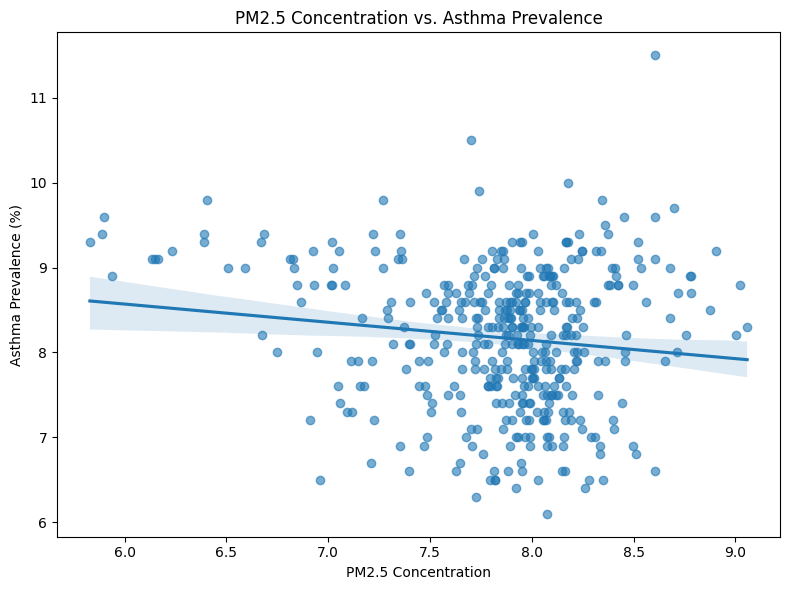

In [11]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=combined,
    x="PM25",
    y="Asthma",
    scatter_kws={"alpha": 0.6}
)

plt.title("PM2.5 Concentration vs. Asthma Prevalence")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Asthma Prevalence (%)")

plt.tight_layout()
plt.savefig("pm25_asthma.png", dpi=300)
plt.show()

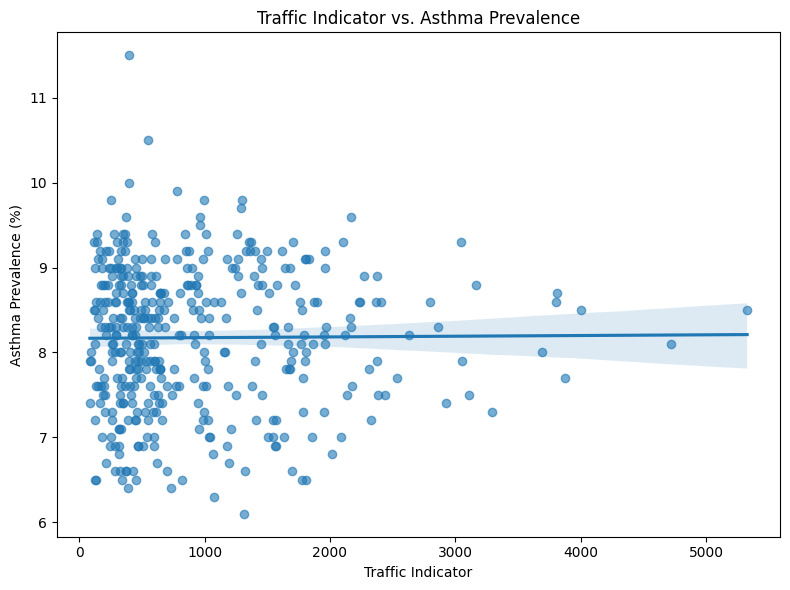

In [12]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=combined,
    x="Traffic",
    y="Asthma",
    scatter_kws={"alpha": 0.6}
)

plt.title("Traffic Indicator vs. Asthma Prevalence")
plt.xlabel("Traffic Indicator")
plt.ylabel("Asthma Prevalence (%)")

plt.tight_layout()
plt.savefig("traffic_asthma.png", dpi=300)
plt.show()

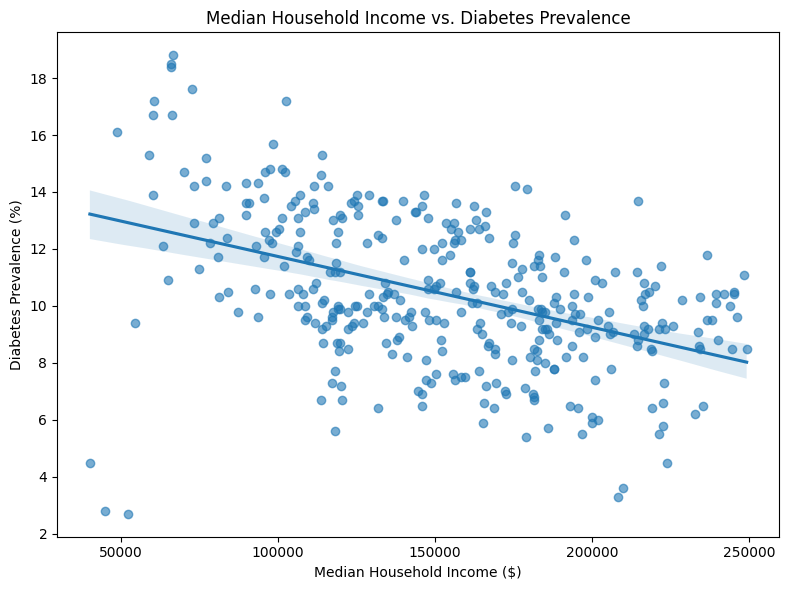

In [13]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=combined,
    x="Income",
    y="Diabetes",
    scatter_kws={"alpha": 0.6}
)

plt.title("Median Household Income vs. Diabetes Prevalence")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Diabetes Prevalence (%)")

plt.tight_layout()
plt.savefig("income_diabetes.png", dpi=300)
plt.show()

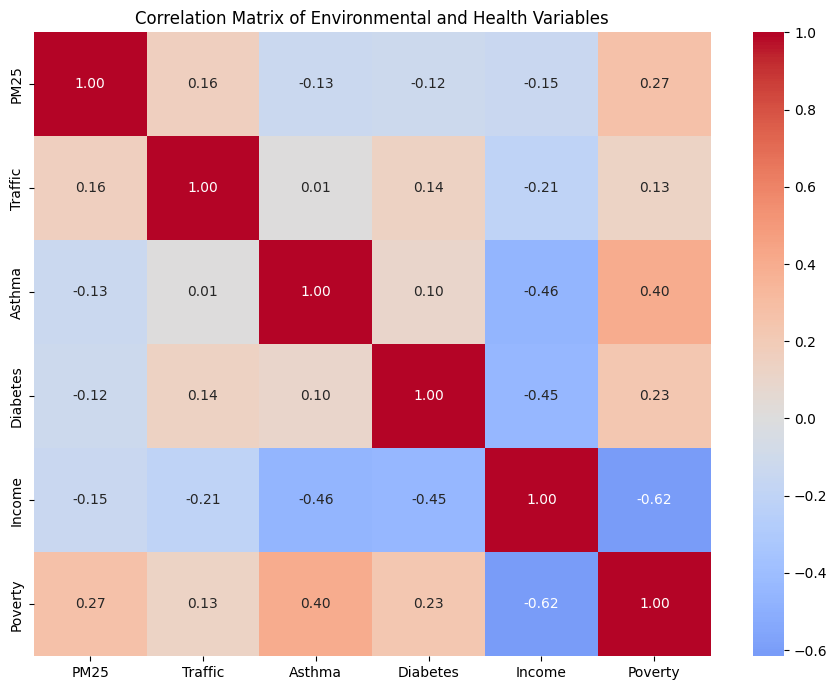

In [14]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    combined[variables].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of Environmental and Health Variables")

plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

In [15]:
correlation_results.to_csv(
    "correlation_results.csv",
    index=False
)

descriptive_stats.to_csv(
    "descriptive_statistics.csv"
)

print("Analysis results saved!")

Analysis results saved!


In [16]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd

pairs = [
    ("PM25", "Asthma"),
    ("PM25", "Diabetes"),
    ("Traffic", "Asthma"),
    ("Traffic", "Diabetes"),
    ("Income", "Asthma"),
    ("Income", "Diabetes"),
    ("Poverty", "Asthma"),
    ("Poverty", "Diabetes"),
    ("Poverty", "PM25"),
    ("Income", "Traffic")
]

results = []

for x, y in pairs:
    data = combined[[x, y]].dropna()

    r, p = pearsonr(data[x], data[y])
    rho, sp = spearmanr(data[x], data[y])

    results.append({
        "Relationship": f"{x} vs. {y}",
        "N": len(data),
        "Pearson r": r,
        "Pearson p": p,
        "Spearman rho": rho,
        "Spearman p": sp
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Relationship,N,Pearson r,Pearson p,Spearman rho,Spearman p
0,PM25 vs. Asthma,408,-0.1320,0.0076,-0.0661,0.1830
1,PM25 vs. Diabetes,408,-0.1203,0.0151,-0.1259,0.0109
2,Traffic vs. Asthma,408,0.0080,0.8721,0.0062,0.9002
3,Traffic vs. Diabetes,408,0.1386,0.0050,0.0223,0.6535
4,Income vs. Asthma,362,-0.4606,0.0000,-0.4357,0.0000
5,Income vs. Diabetes,362,-0.4474,0.0000,-0.4625,0.0000
6,Poverty vs. Asthma,408,0.4021,0.0000,0.2966,0.0000
7,Poverty vs. Diabetes,408,0.2253,0.0000,0.3403,0.0000
8,Poverty vs. PM25,408,0.2679,0.0000,0.3372,0.0000
9,Income vs. Traffic,362,-0.2082,0.0001,-0.1866,0.0004


In [17]:
print("Highest asthma prevalence:")
display(combined.nlargest(10, "Asthma")[
    ["GEOID", "Asthma", "Diabetes", "PM25", "Traffic", "Income", "Poverty"]
])

print("Highest diabetes prevalence:")
display(combined.nlargest(10, "Diabetes")[
    ["GEOID", "Asthma", "Diabetes", "PM25", "Traffic", "Income", "Poverty"]
])

print("Lowest household income:")
display(combined.nsmallest(10, "Income")[
    ["GEOID", "Asthma", "Diabetes", "PM25", "Traffic", "Income", "Poverty"]
])

Highest asthma prevalence:


,GEOID,Asthma,Diabetes,PM25,Traffic,Income,Poverty
8,06085500902,11.5,4.5,8.605823,399.446,40167.0,47.139452
330,06085511608,10.5,2.8,7.701279,552.548,44861.0,31.205674
31,06085502204,10.0,10.9,8.179044,394.283,64904.0,22.100000
406,06085513000,9.9,2.7,7.742934,776.789,52386.0,25.958333
64,06085503123,9.8,13.9,8.345288,993.565,60119.0,12.935197
384,06085512307,9.8,12.0,7.268931,255.305,149531.0,2.102632
407,06085513500,9.8,12.2,6.402862,1300.490,128438.0,10.285220
184,06085505203,9.7,5.6,8.700671,1291.808,118021.0,28.892216
13,06085501300,9.6,10.8,8.605823,374.275,134185.0,19.110611
19,06085501602,9.6,9.4,8.452726,2164.184,54417.0,29.920443


Highest diabetes prevalence:


,GEOID,Asthma,Diabetes,PM25,Traffic,Income,Poverty
79,06085503221,8.0,18.8,8.223982,479.956,66750.0,21.677518
121,06085503713,8.9,18.5,8.103209,2273.007,66002.0,21.144823
120,06085503712,8.6,18.4,8.103209,1871.082,65893.0,22.796834
74,06085503213,8.4,17.6,8.200017,604.497,72686.0,18.229470
54,06085503105,8.0,17.2,8.064088,1809.304,60588.0,15.916955
82,06085503305,7.9,17.2,8.012548,565.268,102500.0,15.105849
77,06085503219,8.4,16.7,8.224250,509.721,60272.0,7.171460
117,06085503709,8.0,16.7,8.459948,462.729,66420.0,22.826273
63,06085503122,8.6,16.1,8.217187,385.651,48750.0,13.427456
81,06085503304,8.0,15.7,8.048946,3690.242,98438.0,12.597343


Lowest household income:


,GEOID,Asthma,Diabetes,PM25,Traffic,Income,Poverty
8,06085500902,11.5,4.5,8.605823,399.446,40167.0,47.139452
330,06085511608,10.5,2.8,7.701279,552.548,44861.0,31.205674
63,06085503122,8.6,16.1,8.217187,385.651,48750.0,13.427456
406,06085513000,9.9,2.7,7.742934,776.789,52386.0,25.958333
19,06085501602,9.6,9.4,8.452726,2164.184,54417.0,29.920443
118,06085503710,8.2,15.3,7.990553,1565.725,58956.0,11.197141
64,06085503123,9.8,13.9,8.345288,993.565,60119.0,12.935197
77,06085503219,8.4,16.7,8.224250,509.721,60272.0,7.171460
54,06085503105,8.0,17.2,8.064088,1809.304,60588.0,15.916955
9,06085501000,9.2,12.1,8.903605,235.975,63291.0,18.522148


In [18]:
import geopandas as gpd

print("GeoPandas version:", gpd.__version__)
print("Dataset columns:", combined.columns.tolist())
print("Number of census tracts:", len(combined))

GeoPandas version: 1.2.0
Dataset columns: ['GEOID', 'PM25', 'Traffic', 'Asthma', 'Diabetes', 'Income', 'Poverty']
Number of census tracts: 408


In [19]:
import geopandas as gpd
import pandas as pd
import requests
import zipfile
import os

# Download California census tract boundaries
url = "https://www2.census.gov/geo/tiger/TIGER2025/TRACT/tl_2025_06_tract.zip"
zip_path = "/content/ca_tracts.zip"

response = requests.get(url)
response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

# Read shapefile
tracts = gpd.read_file(zip_path)

# Keep only Santa Clara County
tracts = tracts[
    (tracts["STATEFP"] == "06") &
    (tracts["COUNTYFP"] == "085")
].copy()

# Standardize GEOID
tracts["GEOID"] = tracts["GEOID"].astype(str).str.zfill(11)

print("Santa Clara County census tracts:", len(tracts))
print("Boundary columns:", tracts.columns.tolist())
print(tracts[["GEOID", "NAME"]].head())

Santa Clara County census tracts: 408
Boundary columns: ['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'GEOIDFQ', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry']
          GEOID     NAME
10  06085507002  5070.02
14  06085504323  5043.23
19  06085511915  5119.15
20  06085504322  5043.22
21  06085512038  5120.38


In [20]:
# Make sure both GEOID columns have the same format
combined["GEOID"] = combined["GEOID"].astype(str).str.zfill(11)

# Join geographic boundaries with environmental health data
map_data = tracts.merge(
    combined,
    on="GEOID",
    how="inner",
    validate="one_to_one"
)

print("Matched census tracts:", len(map_data))
print("Missing geometries:", map_data.geometry.isna().sum())
print("Missing values:")
print(map_data[["Asthma", "Diabetes", "Income", "PM25"]].isna().sum())

Matched census tracts: 408
Missing geometries: 0
Missing values:
Asthma       0
Diabetes     0
Income      46
PM25         0
dtype: int64


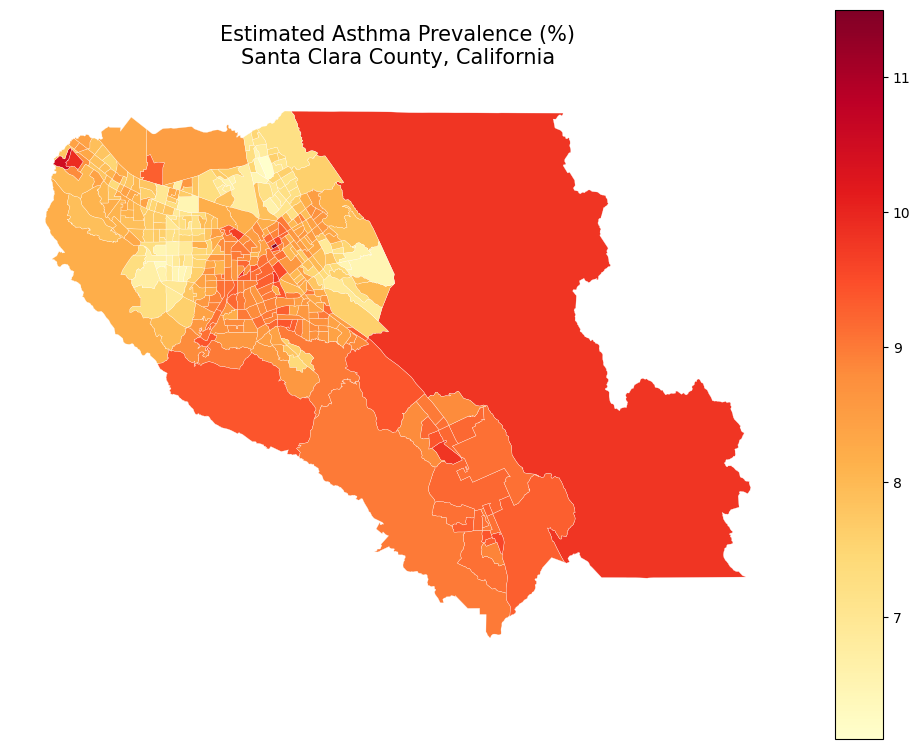

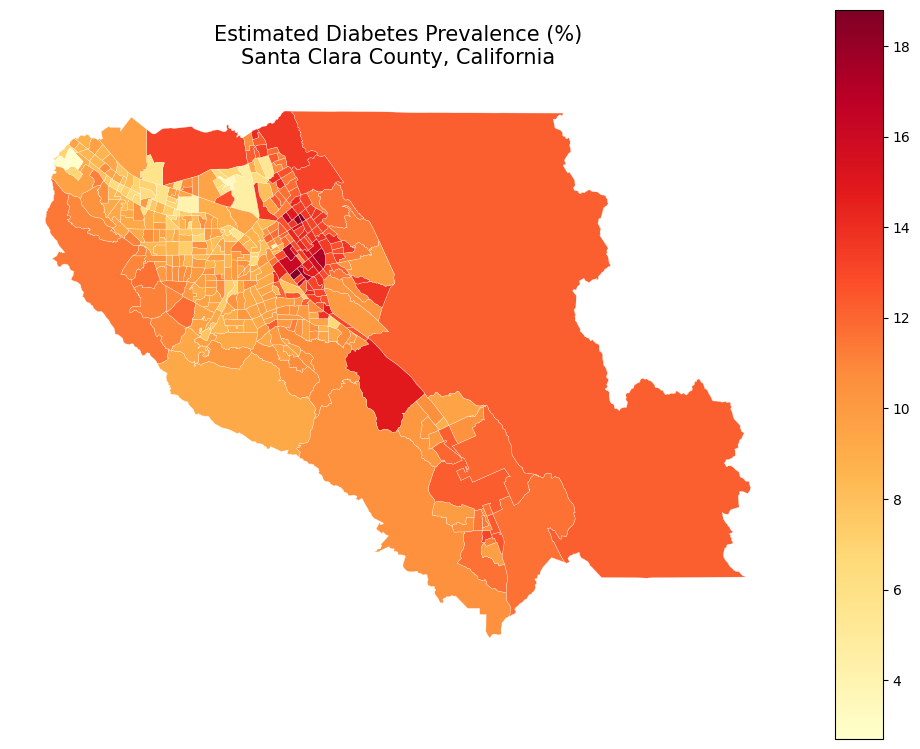

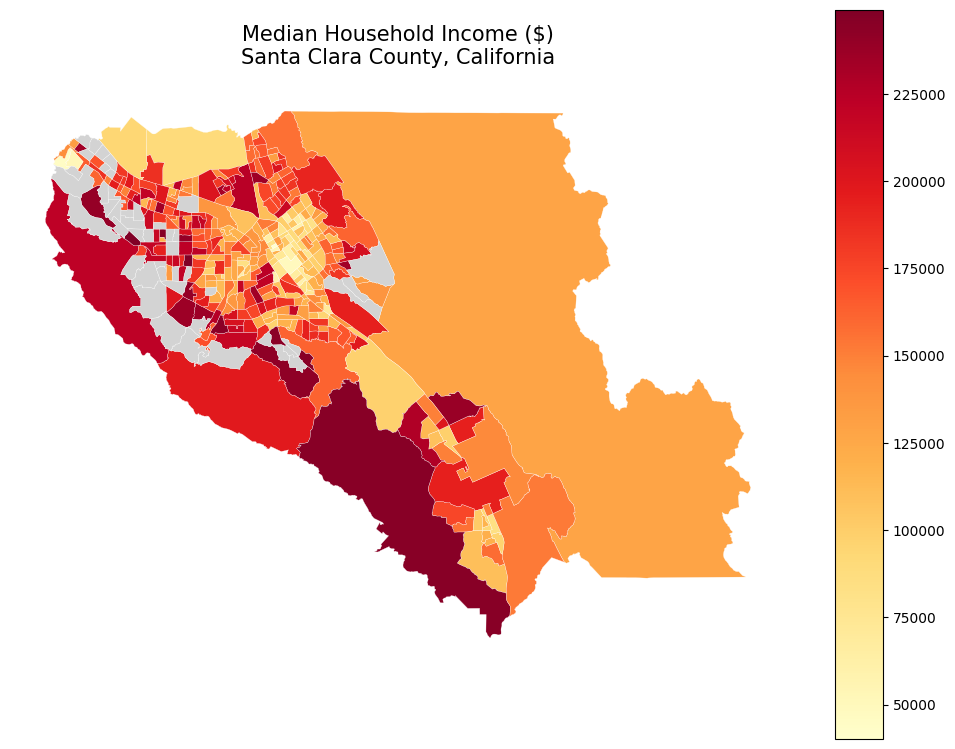

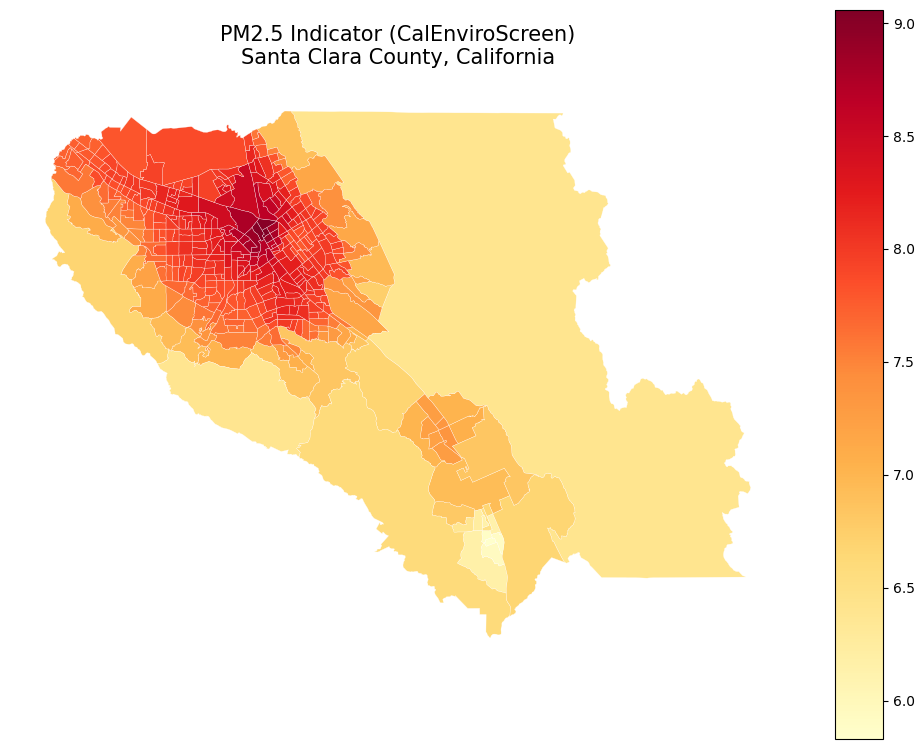

In [21]:
import matplotlib.pyplot as plt

# Variables to map
map_variables = {
    "Asthma": "Estimated Asthma Prevalence (%)",
    "Diabetes": "Estimated Diabetes Prevalence (%)",
    "Income": "Median Household Income ($)",
    "PM25": "PM2.5 Indicator (CalEnviroScreen)"
}

for column, title in map_variables.items():

    fig, ax = plt.subplots(figsize=(10, 10))

    map_data.plot(
        column=column,
        cmap="YlOrRd",
        linewidth=0.2,
        edgecolor="white",
        legend=True,
        missing_kwds={
            "color": "lightgrey",
            "label": "Missing data"
        },
        ax=ax
    )

    ax.set_title(
        title + "\nSanta Clara County, California",
        fontsize=15,
        pad=15
    )

    ax.axis("off")
    plt.tight_layout()

    # Save each map
    filename = f"{column.lower()}_map.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

In [22]:
# Add geographic names to your dataset
tract_info = map_data.copy()

tract_info["centroid"] = tract_info.geometry.centroid
tract_info["longitude"] = tract_info.centroid.x
tract_info["latitude"] = tract_info.centroid.y

# Print the highest-value tracts
for column in ["Asthma", "Diabetes", "PM25"]:
    print(f"\nHighest {column} values:")
    display(
        tract_info.nlargest(10, column)[
            ["GEOID", "NAME", column, "latitude", "longitude"]
        ]
    )

/tmp/ipykernel_1268/2680437581.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  tract_info["centroid"] = tract_info.geometry.centroid
/tmp/ipykernel_1268/2680437581.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  tract_info["longitude"] = tract_info.centroid.x
/tmp/ipykernel_1268/2680437581.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  tract_info["latitude"] = tract_info.centroid.y



Highest Asthma values:


,GEOID,NAME,Asthma,latitude,longitude
379,06085500902,5009.02,11.5,37.333015,-121.879640
208,06085511608,5116.08,10.5,37.428870,-122.177550
101,06085502204,5022.04,10.0,37.301383,-121.925842
249,06085513000,5130,9.9,37.428864,-122.161798
11,06085512307,5123.07,9.8,37.099729,-121.636713
71,06085513500,5135,9.8,37.240038,-121.516785
228,06085503123,5031.23,9.8,37.297730,-121.877836
303,06085505203,5052.03,9.7,37.346718,-121.932789
138,06085501602,5016.02,9.6,37.329325,-121.878186
274,06085501300,5013,9.6,37.338715,-121.874542



Highest Diabetes values:


,GEOID,NAME,Diabetes,latitude,longitude
44,06085503221,5032.21,18.8,37.301295,-121.850115
235,06085503713,5037.13,18.5,37.364725,-121.841006
362,06085503712,5037.12,18.4,37.362287,-121.846643
54,06085503213,5032.13,17.6,37.301672,-121.837368
151,06085503305,5033.05,17.2,37.319874,-121.814680
277,06085503105,5031.05,17.2,37.326198,-121.858758
51,06085503709,5037.09,16.7,37.364549,-121.862042
121,06085503219,5032.19,16.7,37.292524,-121.841760
343,06085503122,5031.22,16.1,37.312491,-121.856932
60,06085503304,5033.04,15.7,37.312610,-121.821222



Highest PM25 values:


,GEOID,NAME,PM25,latitude,longitude
340,06085501101,5011.01,9.058060,37.348096,-121.891967
173,06085500200,5002,9.023723,37.349909,-121.902170
172,06085500100,5001,9.003107,37.358485,-121.892760
380,06085501000,5010,8.903605,37.341642,-121.888071
174,06085500300,5003,8.873493,37.339596,-121.908074
176,06085500600,5006,8.783484,37.333422,-121.914562
25,06085501102,5011.02,8.783013,37.354038,-121.881223
273,06085501200,5012,8.777075,37.346560,-121.878747
296,06085505100,5051,8.756251,37.362814,-121.923993
175,06085500400,5004,8.718033,37.340152,-121.922025


In [23]:
# Reproject to UTM Zone 10N before calculating centroids
projected = map_data.to_crs(epsg=26910)

# Calculate centroids, then convert back to latitude/longitude
centroids = projected.geometry.centroid.to_crs(epsg=4326)

tract_info = map_data.copy()
tract_info["longitude"] = centroids.x
tract_info["latitude"] = centroids.y

In [24]:
from scipy.stats import pearsonr, spearmanr

r, p = pearsonr(combined["Asthma"], combined["Diabetes"])
rho, sp = spearmanr(combined["Asthma"], combined["Diabetes"])

print("Asthma vs. Diabetes")
print("Pearson r:", round(r, 4))
print("Pearson p:", round(p, 6))
print("Spearman rho:", round(rho, 4))
print("Spearman p:", round(sp, 6))

Asthma vs. Diabetes
Pearson r: 0.0977
Pearson p: 0.048546
Spearman rho: 0.1016
Spearman p: 0.040206


In [25]:
!pip install libpysal esda

In [26]:
from libpysal.weights import Queen
from esda.moran import Moran
import pandas as pd

# Create spatial weights based on neighboring census tract boundaries
w = Queen.from_dataframe(map_data, ids="GEOID")
w.transform = "r"

print("Number of tracts:", len(w.id_order))
print("Number of isolated tracts:", len(w.islands))

Number of tracts: 408
Number of isolated tracts: 0


In [27]:
variables = ["Asthma", "Diabetes", "PM25", "Traffic"]

moran_results = []

for variable in variables:

    moran = Moran(
        map_data[variable].values,
        w,
        permutations=999
    )

    moran_results.append({
        "Variable": variable,
        "Moran's I": moran.I,
        "Expected I": moran.EI,
        "Permutation p-value": moran.p_sim
    })

moran_df = pd.DataFrame(moran_results)

display(moran_df.round(4))

,Variable,Moran's I,Expected I,Permutation p-value
0,Asthma,0.7293,-0.0025,0.001
1,Diabetes,0.6161,-0.0025,0.001
2,PM25,0.9023,-0.0025,0.001
3,Traffic,0.4765,-0.0025,0.001
